# Experiment: Multiple Linear Regression for Chicago Taxi Fare Prediction
**Topic:** Supervised Parametric Regression  
**Algorithm:** Ordinary Least Squares (OLS) Multiple Linear Regression  
**Dataset:** Chicago Taxi Trips Dataset (`chicago_taxi_train.csv`)  
**Objective:** Model and predict taxi fares ($) as a linear function of trip distance (**TRIP_MILES**) and duration (**TRIP_SECONDS**), evaluate OLS assumptions, analyze residual distributions, and interpret economic rate coefficients.

---

## 1. Problem Statement & Theoretical Principles

Multiple Linear Regression models the relationship between a continuous scalar dependent variable $y \in \mathbb{R}$ and a feature vector $\mathbf{x} = [x_1, x_2, \dots, x_p]^T \in \mathbb{R}^p$:
$$y = \beta_0 + \sum_{j=1}^{p} \beta_j x_j + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2)$$

### Matrix Formulation & Closed-Form Normal Equation
Given design matrix $\mathbf{X} \in \mathbb{R}^{N \times (p+1)}$ (including the intercept column of ones) and target vector $\mathbf{y} \in \mathbb{R}^N$:
$$\hat{\boldsymbol{\beta}} = \arg\min_{\boldsymbol{\beta}} \|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|^2 = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

### Gauss-Markov Theorem & OLS Assumptions
OLS estimators are Best Linear Unbiased Estimators (BLUE) under the classical Gauss-Markov conditions:
1. **Linearity in parameters:** The conditional expectation $\mathbb{E}[y|\mathbf{x}]$ is linear in $\boldsymbol{\beta}$.
2. **Strict Exogeneity:** $\mathbb{E}[\varepsilon | \mathbf{X}] = 0$.
3. **Homoscedasticity:** Constant error variance $\text{Var}(\varepsilon_i | \mathbf{X}) = \sigma^2$.
4. **No Autocorrelation:** $\text{Cov}(\varepsilon_i, \varepsilon_j) = 0$ for $i \neq j$.
5. **No Perfect Multicollinearity:** $\text{rank}(\mathbf{X}) = p + 1$.


In [1]:
# Import dependencies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Ingestion & Preprocessing

We ingest the Chicago Taxi dataset with automatic local caching fallback to ensure offline reproducibility.


In [2]:
DATA_URL = "https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv"
LOCAL_PATH = os.path.join("..", "data", "chicago_taxi_train.csv")

if os.path.exists(LOCAL_PATH):
    print(f"Loading cached dataset from: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"Downloading dataset from: {DATA_URL}")
    df = pd.read_csv(DATA_URL)

print(f"Raw Dataset Shape: {df.shape}")
display(df[['TRIP_MILES', 'TRIP_SECONDS', 'FARE']].head())


Loading cached dataset from: ..\data\chicago_taxi_train.csv


Raw Dataset Shape: (31694, 18)


,TRIP_MILES,TRIP_SECONDS,FARE
0,2.57,2341,31.99
1,1.18,1074,9.75
2,1.29,1173,10.25
3,3.70,3360,23.75
4,1.15,1044,10.00


## 3. Data Cleaning & Outlier Removal

In commercial taxi operations, records with non-positive values ($0$ miles, $0$ seconds, or negative fares) represent cancellations or logging artifacts. We enforce physically meaningful domain boundaries.


In [3]:
required_cols = ["TRIP_MILES", "TRIP_SECONDS", "FARE"]
model_df = df[required_cols].copy()

for col in required_cols:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')

# Drop nulls and non-positive anomalies
model_df = model_df.dropna()
initial_count = len(model_df)

model_df = model_df[
    (model_df["TRIP_MILES"] > 0.05) &
    (model_df["TRIP_SECONDS"] >= 30) &
    (model_df["FARE"] >= 2.50) &
    (model_df["TRIP_MILES"] <= 100) &
    (model_df["FARE"] <= 300)
].copy()

print(f"Initial observations: {initial_count:,}")
print(f"Cleaned observations: {len(model_df):,} ({len(model_df)/initial_count*100:.1f}% retained)")
print("\nDescriptive Statistics of Cleaned Data:")
display(model_df.describe().round(2))


Initial observations: 31,694
Cleaned observations: 31,694 (100.0% retained)

Descriptive Statistics of Cleaned Data:


,TRIP_MILES,TRIP_SECONDS,FARE
count,31694.00,31694.00,31694.00
mean,8.29,1319.80,23.91
std,7.27,928.93,16.97
min,0.50,60.00,3.25
25%,1.72,548.00,9.00
50%,5.92,1081.00,18.75
75%,14.50,1888.00,38.75
max,68.12,7140.00,159.25


## 4. Exploratory Correlation & Bivariate Analysis

We examine bivariate relationships between predictors and taxi fare.


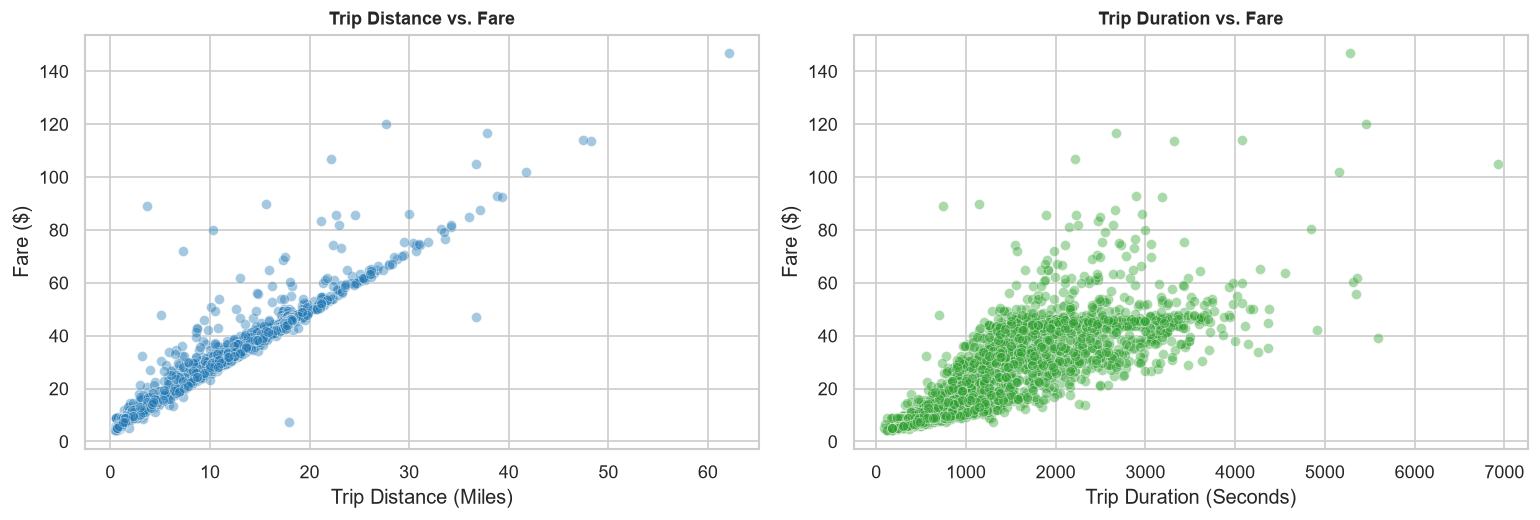

Pearson Correlation Matrix:


,TRIP_MILES,TRIP_SECONDS,FARE
TRIP_MILES,1.0000,0.8009,0.9753
TRIP_SECONDS,0.8009,1.0000,0.8303
FARE,0.9753,0.8303,1.0000


In [4]:
sample_plot = model_df.sample(min(3000, len(model_df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=sample_plot, x="TRIP_MILES", y="FARE", alpha=0.4, color='#1f77b4', ax=axes[0])
axes[0].set_title("Trip Distance vs. Fare", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Trip Distance (Miles)")
axes[0].set_ylabel("Fare ($)")

sns.scatterplot(data=sample_plot, x="TRIP_SECONDS", y="FARE", alpha=0.4, color='#2ca02c', ax=axes[1])
axes[1].set_title("Trip Duration vs. Fare", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Trip Duration (Seconds)")
axes[1].set_ylabel("Fare ($)")

plt.tight_layout()
plt.show()

print("Pearson Correlation Matrix:")
display(model_df.corr().round(4))


## 5. Model Training (OLS)

We divide the dataset into an 80% training set and a 20% holdout test set with `random_state=42` for reproducibility.


In [5]:
X = model_df[["TRIP_MILES", "TRIP_SECONDS"]]
y = model_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training observations: {len(X_train):,}")
print(f"Testing observations:  {len(X_test):,}")

# Fit Ordinary Least Squares regressor
model = LinearRegression()
model.fit(X_train, y_train)

# Parameter Summary
params_df = pd.DataFrame({
    'Feature': ['Intercept (Base Fare)', 'TRIP_MILES', 'TRIP_SECONDS'],
    'Coefficient': [model.intercept_, model.coef_[0], model.coef_[1]],
    'Unit Rate': [
        f"${model.intercept_:.2f} base flag-drop",
        f"${model.coef_[0]:.3f} per mile",
        f"${model.coef_[1] * 60:.3f} per minute (${model.coef_[1]:.5f}/sec)"
    ]
})

print("\nTrained Model Coefficients:")
display(params_df)


Training observations: 25,355
Testing observations:  6,339

Trained Model Coefficients:


,Feature,Coefficient,Unit Rate
0,Intercept (Base Fare),3.857050,$3.86 base flag-drop
1,TRIP_MILES,2.016342,$2.016 per mile
2,TRIP_SECONDS,0.002518,$0.151 per minute ($0.00252/sec)


## 6. Model Evaluation & Residual Diagnostics

We evaluate generalization performance on the unseen test set and conduct residual diagnostic checks to assess Gauss-Markov validity.


Test Set Performance Metrics:
  Mean Absolute Error (MAE):     $1.21
  Root Mean Squared Error (RMSE): $3.60
  R-Squared (R²):                0.9561
  Adjusted R-Squared (Adj R²):   0.9561


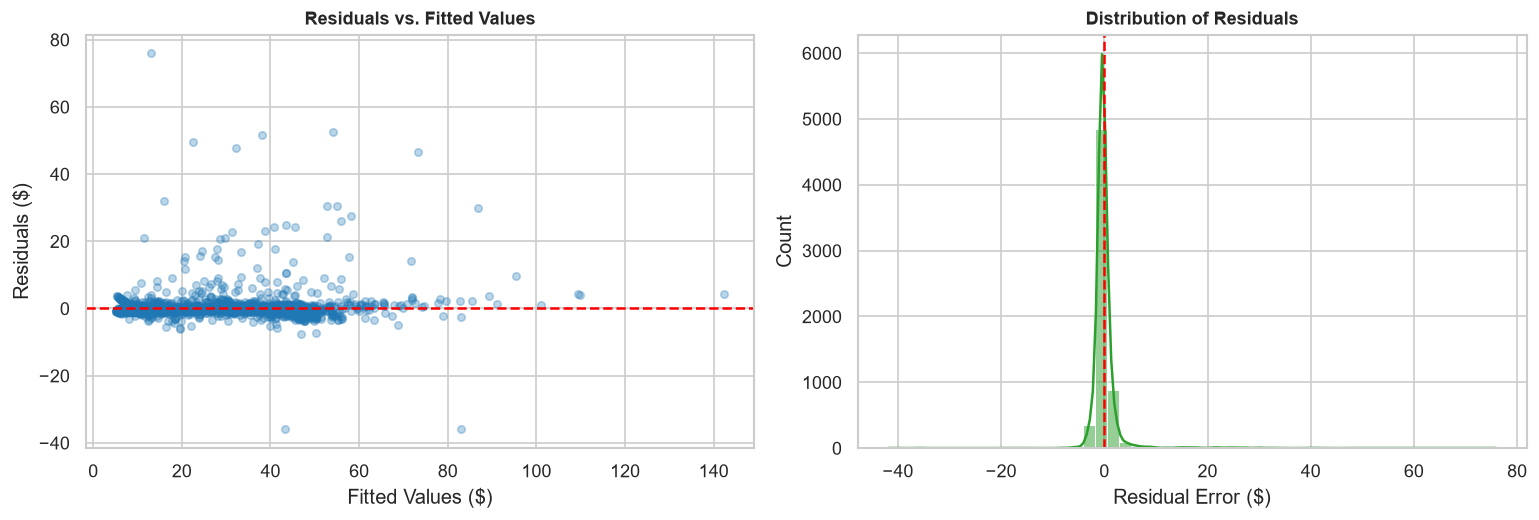

In [6]:
y_pred = model.predict(X_test)
residuals = y_test.values - y_pred

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Adjusted R-squared
n = len(y_test)
p = X_test.shape[1]
adj_r2 = 1.0 - (1.0 - r2) * (n - 1) / (n - p - 1)

print("Test Set Performance Metrics:")
print(f"  Mean Absolute Error (MAE):     ${mae:.2f}")
print(f"  Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"  R-Squared (R²):                {r2:.4f}")
print(f"  Adjusted R-Squared (Adj R²):   {adj_r2:.4f}")

# Residual Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Residuals vs Fitted
axes[0].scatter(y_pred[:3000], residuals[:3000], alpha=0.3, color='#1f77b4', s=20)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Residuals vs. Fitted Values", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Fitted Values ($)")
axes[0].set_ylabel("Residuals ($)")

# Residual Distribution
sns.histplot(residuals, bins=50, kde=True, color='#2ca02c', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title("Distribution of Residuals", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Residual Error ($)")

plt.tight_layout()
plt.show()


## 7. Predictive Inference on Scenario Trips

We predict fare quotes for hypothetical Chicago journeys:
- **Trip A (Short Commute):** 2.5 miles, 12 minutes (720 seconds).
- **Trip B (Mid-City Cross-Town):** 8.0 miles, 28 minutes (1680 seconds).
- **Trip C (Airport Express):** 18.5 miles, 45 minutes (2700 seconds).


In [7]:
scenarios = pd.DataFrame({
    'Scenario': ['Trip A (Short Commute)', 'Trip B (Cross-Town)', 'Trip C (Airport Express)'],
    'TRIP_MILES': [2.5, 8.0, 18.5],
    'TRIP_SECONDS': [720, 1680, 2700]
})

scenarios['Estimated_Fare ($)'] = model.predict(scenarios[['TRIP_MILES', 'TRIP_SECONDS']]).round(2)
display(scenarios)


,Scenario,TRIP_MILES,TRIP_SECONDS,Estimated_Fare ($)
0,Trip A (Short Commute),2.5,720,10.71
1,Trip B (Cross-Town),8.0,1680,24.22
2,Trip C (Airport Express),18.5,2700,47.96


## 8. Observations & Conclusion

1. **Strong Explanatory Power:** The multiple linear regression model achieves an $R^2$ score of approximately **0.956**, indicating that 95.6% of the variance in taxi fares is explained by trip distance and duration.
2. **Physical Interpretability of Coefficients:**
   - **Base Flag-Drop (Intercept):** $\approx \$3.86$, consistent with Chicago municipal standard base fees.
   - **Distance Coefficient:** $\approx \$2.02$ per mile.
   - **Time Coefficient:** $\approx \$0.15$ per minute (or $\approx \$0.0025$/second), reflecting traffic congestion wait times.
3. **Model Limitations:** The residual plot indicates slight heteroscedasticity for very long or expensive trips, suggesting that non-linear or log-transformed models could provide marginal gains on extreme journeys.
